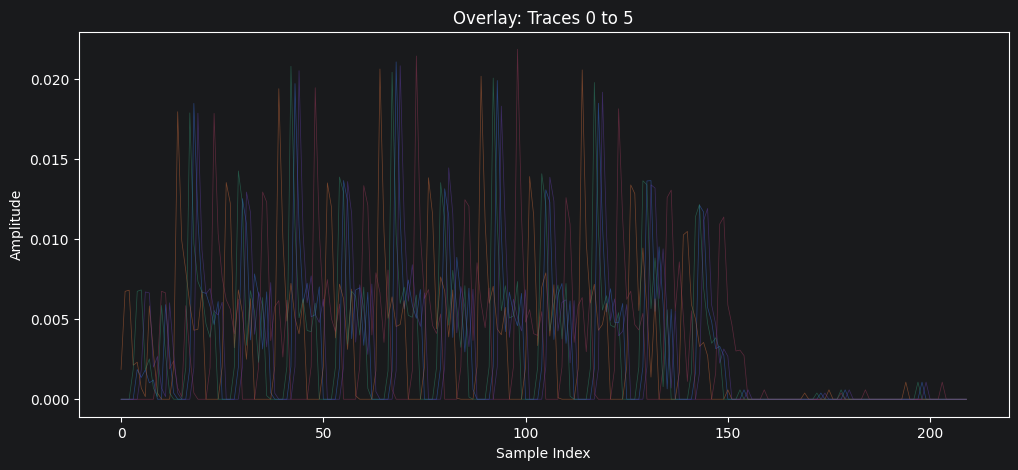

999
210


In [1]:
from scapyter.ui.trace_plotter import TracePlotter


from scapyter.domain.value_object import Range
from scapyter.infrastructure.h5.readers.h5_project_file_reader import H5ProjectFileReader


input_file_path = "random_de_sync_simulated_design.sx"

desync_project = H5ProjectFileReader(input_file_path)
trace_plotter = TracePlotter(desync_project)
trace_plotter.plot_overlay(trace_range=Range(0,5))
print(desync_project.trace_count)
print(desync_project.sample_count)

In [2]:
from scapyter.domain.analysis.correlation.service import CorrelationService
from scapyter.domain.analysis.correlation.value_objects.correlation_functions import CorrelationFunction
from scapyter.domain.targets.targets import ShiftRowsInvSboxXor
from scapyter.domain.leakage_functions.leakage_functions import HammingWeight
from scapyter.domain.leakage_model.leakage_model import LeakageModel
from scapyter.domain.analysis.correlation.cpa import CpaCorrelation
from scapyter.domain.value_object import RangeParameters, KeyByteGuesses, DataSource

range_parameter = RangeParameters(
    trace_range=Range(0, 999),
    sample_range=Range(130, 160),
)

correlation_functions = [
    CorrelationFunction(
        correlation=CpaCorrelation(),
        leakage_model=LeakageModel(
            target=ShiftRowsInvSboxXor(),
            leakage_function=HammingWeight(),
            byte_location=i,
            key_byte_guesses=KeyByteGuesses.from_full256_range()
        ),
    )
    for i in range(16)
]


results = []
for fun in correlation_functions:

    result = CorrelationService(
        range_parameters=range_parameter,
        project_file_reader=desync_project,
        data_source=DataSource.CIPHERTEXT,
    ).run(fun)
    results.append(result)

Byte 15: 100%|██████████| 20/20 [00:00<00:00, 551.44batch/s]


In [3]:
from scapyter.ui.key_rank_visualizer import KeyRankVisualizer

visualizer = KeyRankVisualizer(results)

# 2. Display the table
# This will show the top 5 candidates for every byte
visualizer.display_rank_table(top_n=5)

# 3. Print the final guessed key hex string
guessed_key = visualizer.get_full_key_guess()
print(f"Guessed Key: {guessed_key.hex().upper()}")

,Byte 00,Byte 01,Byte 02,Byte 03,Byte 04,Byte 05,Byte 06,Byte 07,Byte 08,Byte 09,Byte 10,Byte 11,Byte 12,Byte 13,Byte 14,Byte 15
Rank 1,BB (0.121),00 (0.127),2F (0.110),0C (0.133),39 (0.113),FB (0.109),19 (0.112),55 (0.112),6C (0.110),B7 (0.141),B8 (0.129),AF (0.119),F7 (0.133),F8 (0.135),5A (0.121),1A (0.124)
Rank 2,8A (0.111),A7 (0.117),8F (0.110),A4 (0.114),E8 (0.112),8A (0.106),3B (0.108),13 (0.109),A5 (0.110),AA (0.135),D3 (0.116),DD (0.115),AF (0.114),B0 (0.106),8E (0.119),8E (0.111)
Rank 3,01 (0.109),B5 (0.105),BF (0.110),B8 (0.110),73 (0.111),F9 (0.105),E9 (0.107),19 (0.105),13 (0.109),F1 (0.108),31 (0.111),FB (0.114),E6 (0.108),55 (0.103),C3 (0.113),5C (0.105)
Rank 4,F1 (0.106),71 (0.103),78 (0.106),CE (0.105),79 (0.108),CD (0.101),6F (0.101),34 (0.105),4F (0.108),E6 (0.107),F5 (0.110),B6 (0.105),78 (0.104),65 (0.103),86 (0.112),78 (0.103)
Rank 5,2D (0.105),EB (0.102),A2 (0.104),25 (0.104),A0 (0.106),26 (0.099),04 (0.101),0B (0.103),8D (0.107),24 (0.106),0E (0.107),70 (0.102),60 (0.103),BB (0.102),8B (0.111),14 (0.103)


Guessed Key: BB002F0C39FB19556CB7B8AFF7F85A1A


In [7]:
from scapyter.domain.signal_processing.resync.sad import SADResyncProcessor
from scapyter.application.trace_processing_service import TraceProcessingService

ref_trace = desync_project.get_single_batch(0).trace
output_file_path = "resync_simulated_design.sx"
processor = SADResyncProcessor(reference_trace=ref_trace, reference_range=Range(140, 155), search_range=Range(130, 165))
service = TraceProcessingService(input_file_path, output_file_path, processor)
service.run()

Processing traces: 100%|██████████| 10/10 [00:00<00:00, 128.74batch/s]


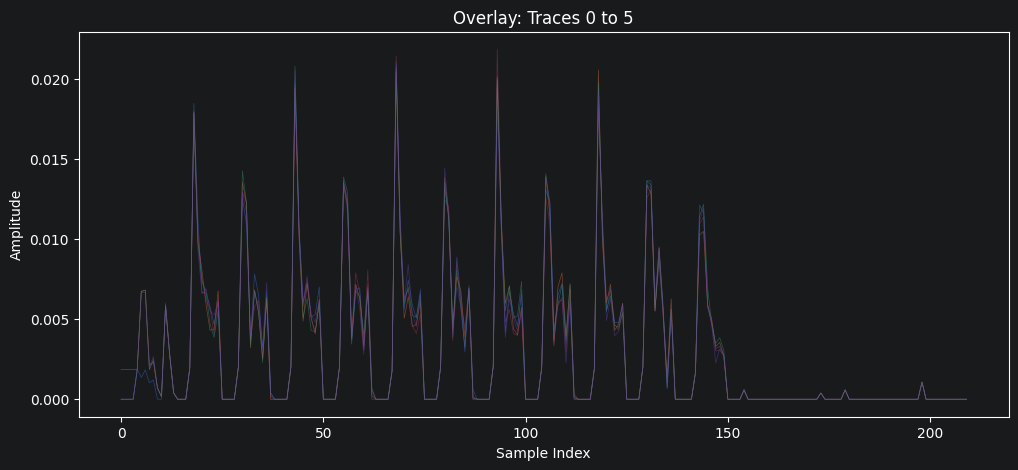

999
210


In [8]:
sync_project = H5ProjectFileReader(output_file_path)
trace_plotter = TracePlotter(desync_project)
trace_plotter.plot_overlay(trace_range=Range(0,5))
print(sync_project.trace_count)
print(sync_project.sample_count)

In [9]:
range_parameter = RangeParameters(
    trace_range=Range(0, 999),
    sample_range=Range(130, 160),
)

correlation_functions = [
    CorrelationFunction(
        correlation=CpaCorrelation(),
        leakage_model=LeakageModel(
            target=ShiftRowsInvSboxXor(),
            leakage_function=HammingWeight(),
            byte_location=i,
            key_byte_guesses=KeyByteGuesses.from_full256_range()
        ),
    )
    for i in range(16)
]


results = []
for fun in correlation_functions:

    result = CorrelationService(
        range_parameters=range_parameter,
        project_file_reader=sync_project,
        data_source=DataSource.CIPHERTEXT,
    ).run(fun)
    results.append(result)

Byte 15: 100%|██████████| 20/20 [00:00<00:00, 530.36batch/s]


In [10]:
from scapyter.ui.key_rank_visualizer import KeyRankVisualizer

visualizer = KeyRankVisualizer(results)

# 2. Display the table
# This will show the top 5 candidates for every byte
visualizer.display_rank_table(top_n=5)

# 3. Print the final guessed key hex string
guessed_key = visualizer.get_full_key_guess()
print(f"Guessed Key: {guessed_key.hex().upper()}")

,Byte 00,Byte 01,Byte 02,Byte 03,Byte 04,Byte 05,Byte 06,Byte 07,Byte 08,Byte 09,Byte 10,Byte 11,Byte 12,Byte 13,Byte 14,Byte 15
Rank 1,13 (0.161),11 (0.142),1D (0.218),7F (0.140),E3 (0.235),94 (0.160),4A (0.140),17 (0.157),F3 (0.250),07 (0.183),A7 (0.216),8B (0.196),4D (0.214),2B (0.193),30 (0.185),C5 (0.186)
Rank 2,30 (0.113),02 (0.108),3E (0.114),B9 (0.133),83 (0.146),1E (0.108),76 (0.125),14 (0.119),43 (0.132),47 (0.111),43 (0.128),96 (0.113),90 (0.121),26 (0.119),43 (0.123),1D (0.116)
Rank 3,A7 (0.110),EE (0.104),75 (0.113),9D (0.112),3E (0.114),FF (0.102),99 (0.106),5A (0.110),AA (0.131),9E (0.109),3A (0.121),CE (0.108),64 (0.118),71 (0.117),80 (0.112),96 (0.114)
Rank 4,1E (0.110),AC (0.103),F2 (0.113),91 (0.112),B4 (0.114),4C (0.102),A3 (0.103),55 (0.109),42 (0.118),41 (0.103),A4 (0.116),8D (0.105),5F (0.117),C0 (0.112),2E (0.112),0F (0.110)
Rank 5,8D (0.109),A3 (0.102),1E (0.108),AC (0.110),E1 (0.113),5A (0.102),90 (0.099),7F (0.109),7A (0.108),E5 (0.100),2F (0.108),6C (0.101),2A (0.116),0A (0.104),F8 (0.109),EA (0.106)


Guessed Key: 13111D7FE3944A17F307A78B4D2B30C5
